<a href="https://colab.research.google.com/github/independentmisfit/NIBSS-FRAUD/blob/main/NIBSS_FRAUD_DATA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [108]:
# 1. Install the Kaggle library
!pip install -q kaggle

# 2. Trigger a file upload prompt to select your 'kaggle.json' file
from google.colab import files
files.upload()


Saving kaggle.json to kaggle (3).json


{'kaggle (3).json': b'{"username":"zehro0","key":"4a857390ddaf9d2c66245e19076ad93d"}'}

In [109]:
import os

# Create the hidden directory if it doesn't exist
!mkdir -p ~/.kaggle

# Move the uploaded token file into the correct hidden folder
!cp kaggle.json ~/.kaggle/

# Set strict read/write permissions for security reasons
!chmod 600 ~/.kaggle/kaggle.json


In [110]:
# Replace 'username/dataset-name' with your actual dataset string
!kaggle datasets download -d hendurhance/nibsss-fraud-dataset

# Unzip the downloaded file (replace 'dataset-name' with your actual file name)
!unzip -q nibsss-fraud-dataset.zip -d ./data


Dataset URL: https://www.kaggle.com/datasets/hendurhance/nibsss-fraud-dataset
License(s): CC-BY-SA-4.0
nibsss-fraud-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace ./data/data_dictionary.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


In [111]:
import numpy as np
import pandas as pd

In [112]:
df = pd.read_csv("/content/data/nibss_fraud_dataset.csv")
df.head()

/tmp/ipykernel_5201/1283813271.py:1: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/data/nibss_fraud_dataset.csv")


,transaction_id,customer_id,timestamp,amount,channel,merchant_category,bank,location,age_group,hour,day_of_week,month,is_weekend,is_peak_hour,tx_count_24h,amount_sum_24h,amount_mean_7d,amount_std_7d,tx_count_total,amount_mean_total,amount_std_total,channel_diversity,location_diversity,amount_vs_mean_ratio,online_channel_ratio,is_fraud,fraud_technique,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos,amount_log,amount_rounded,velocity_score,merchant_risk_score,composite_risk
0,TXN_F08A86FFD87C,CUST_0002AED1,2023-01-14 04:31:09,32266.83,Mobile,Grocery,Sterling,Other,30-39,4,5,1,True,False,1.0,32266.83,32266.830000,0.000000,107,170389.868692,365915.900271,5,1,0.189369,0.775701,0,NaN,0.866025,0.500000,-0.974928,-0.222521,0.500000,0.866025,10.381826,0,0.189369,0.215000,0.070560
1,TXN_C2D08134EC83,CUST_0002AED1,2023-01-17 11:20:13,72530.49,Web,Entertainment,UBA,Other,30-39,11,1,1,False,True,1.0,72530.49,52398.660000,20131.830000,107,170389.868692,365915.900271,5,1,0.425671,0.775701,0,NaN,0.258819,-0.965926,0.781831,0.623490,0.500000,0.866025,11.191776,0,0.425671,0.877424,0.276849
2,TXN_B9499111901D,CUST_0002AED1,2023-01-22 02:17:46,168152.87,Mobile,Transport,Wema,Other,30-39,2,6,1,True,False,1.0,168152.87,120341.680000,47811.190000,107,170389.868692,365915.900271,5,1,0.986866,0.775701,0,NaN,0.500000,0.866025,-0.781831,0.623490,0.500000,0.866025,12.032635,0,0.986866,0.440230,0.163649
3,TXN_48DB1D526A3B,CUST_0002AED1,2023-01-24 08:18:23,16439.93,Mobile,Entertainment,FCMB,Other,30-39,8,1,1,False,False,1.0,16439.93,85707.763333,62633.507753,107,170389.868692,365915.900271,5,1,0.096484,0.775701,0,NaN,0.866025,-0.500000,0.781831,0.623490,0.500000,0.866025,9.707529,0,0.096484,0.877424,0.266315
4,TXN_56DB1E28B758,CUST_0002AED1,2023-02-01 15:39:53,9922.68,POS,Education,FirstBank,Other,30-39,15,2,2,False,True,1.0,9922.68,9922.680000,0.000000,107,170389.868692,365915.900271,5,1,0.058235,0.775701,0,NaN,-0.707107,-0.707107,0.974928,-0.222521,0.866025,0.500000,9.202679,0,0.058235,0.231291,0.071251


In [113]:
df.columns

Index(['transaction_id', 'customer_id', 'timestamp', 'amount', 'channel',
       'merchant_category', 'bank', 'location', 'age_group', 'hour',
       'day_of_week', 'month', 'is_weekend', 'is_peak_hour', 'tx_count_24h',
       'amount_sum_24h', 'amount_mean_7d', 'amount_std_7d', 'tx_count_total',
       'amount_mean_total', 'amount_std_total', 'channel_diversity',
       'location_diversity', 'amount_vs_mean_ratio', 'online_channel_ratio',
       'is_fraud', 'fraud_technique', 'hour_sin', 'hour_cos', 'day_sin',
       'day_cos', 'month_sin', 'month_cos', 'amount_log', 'amount_rounded',
       'velocity_score', 'merchant_risk_score', 'composite_risk'],
      dtype='object')

### 1. Initial Data Overview

In [114]:
# Display concise summary of the DataFrame, including data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 38 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   transaction_id        1000000 non-null  object 
 1   customer_id           1000000 non-null  object 
 2   timestamp             1000000 non-null  object 
 3   amount                1000000 non-null  float64
 4   channel               1000000 non-null  object 
 5   merchant_category     1000000 non-null  object 
 6   bank                  1000000 non-null  object 
 7   location              1000000 non-null  object 
 8   age_group             1000000 non-null  object 
 9   hour                  1000000 non-null  int64  
 10  day_of_week           1000000 non-null  int64  
 11  month                 1000000 non-null  int64  
 12  is_weekend            1000000 non-null  bool   
 13  is_peak_hour          1000000 non-null  bool   
 14  tx_count_24h          1000000 non-n

In [115]:
# Display descriptive statistics for numerical columns
df.describe()

,amount,hour,day_of_week,month,tx_count_24h,amount_sum_24h,amount_mean_7d,amount_std_7d,tx_count_total,amount_mean_total,amount_std_total,channel_diversity,location_diversity,amount_vs_mean_ratio,online_channel_ratio,is_fraud,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos,amount_log,amount_rounded,velocity_score,merchant_risk_score,composite_risk
count,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1.000000e+06,1.000000e+06,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.0,1000000.000000,1000000.000000,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,1.569514e+05,12.228639,3.013070,6.609283,1.282159,1.991769e+05,1.557863e+05,1.112951e+05,100.985146,156224.102273,2.901578e+05,5.864267,1.0,0.999993,0.700237,0.00300,-0.085920,-0.466445,-0.001601,-0.003539,3.397843e-02,1.272586e-02,11.110517,0.000079,1.905117,0.395645,0.151286
std,3.263590e+05,4.798625,1.997767,3.464179,0.533265,3.742924e+05,2.184174e+05,2.091671e+05,9.900881,32450.494993,1.435335e+05,0.343522,0.0,1.858192,0.045526,0.05469,0.653980,0.589371,0.707580,0.706623,7.197222e-01,6.933142e-01,1.302152,0.008888,3.915378,0.238704,0.087124
min,1.685500e+02,0.000000,0.000000,1.000000,1.000000,1.685500e+02,2.128300e+02,0.000000e+00,61.000000,79531.073708,7.629456e+04,4.000000,1.0,0.001013,0.524390,0.00000,-1.000000,-1.000000,-0.974928,-0.900969,-1.000000e+00,-1.000000e+00,5.133148,0.000000,0.001077,0.121274,0.036431
25%,2.800042e+04,9.000000,1.000000,3.000000,1.000000,3.617210e+04,5.327417e+04,1.421574e+04,94.000000,133244.011525,1.980980e+05,6.000000,1.0,0.181893,0.670000,0.00000,-0.707107,-0.866025,-0.781831,-0.900969,-5.000000e-01,-5.000000e-01,10.240010,0.000000,0.246675,0.202718,0.078078
50%,6.667998e+04,12.000000,3.000000,7.000000,1.000000,8.971861e+04,9.779375e+04,5.121962e+04,101.000000,151366.221635,2.528541e+05,6.000000,1.0,0.437315,0.701613,0.00000,0.000000,-0.707107,0.000000,-0.222521,-2.449294e-16,6.123234e-17,11.107675,0.000000,0.681163,0.369588,0.135629
75%,1.595289e+05,15.000000,5.000000,10.000000,1.000000,2.150990e+05,1.795145e+05,1.246082e+05,107.000000,174289.988391,3.373644e+05,6.000000,1.0,1.049607,0.730769,0.00000,0.500000,-0.258819,0.781831,0.623490,8.660254e-01,5.000000e-01,11.979987,0.000000,1.915726,0.542436,0.196458
max,1.792681e+07,23.000000,6.000000,12.000000,6.000000,1.326406e+07,1.000000e+07,4.998794e+06,140.000000,380508.803514,1.149815e+06,6.000000,1.0,54.904026,0.892857,1.00000,1.000000,1.000000,0.974928,1.000000,1.000000e+00,1.000000e+00,16.701808,1.000000,191.519506,0.877424,0.734583


In [116]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

Missing values per column:
fraud_technique    997000
dtype: int64


### 2. Data Cleaning and Preprocessing

In [117]:
# Convert 'timestamp' to datetime objects
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Verify the conversion
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 38 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   transaction_id        1000000 non-null  object        
 1   customer_id           1000000 non-null  object        
 2   timestamp             1000000 non-null  datetime64[ns]
 3   amount                1000000 non-null  float64       
 4   channel               1000000 non-null  object        
 5   merchant_category     1000000 non-null  object        
 6   bank                  1000000 non-null  object        
 7   location              1000000 non-null  object        
 8   age_group             1000000 non-null  object        
 9   hour                  1000000 non-null  int64         
 10  day_of_week           1000000 non-null  int64         
 11  month                 1000000 non-null  int64         
 12  is_weekend            1000000 non-null  boo

### 3. Exploratory Data Analysis (EDA)

#### 3.1 Target Variable Analysis: `is_fraud`

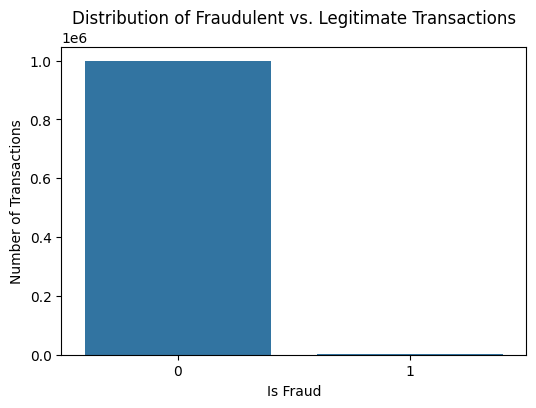

Percentage of fraudulent transactions: 0.3000%
Percentage of legitimate transactions: 99.7000%


In [118]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of 'is_fraud'
plt.figure(figsize=(6, 4))
sns.countplot(x='is_fraud', data=df)
plt.title('Distribution of Fraudulent vs. Legitimate Transactions')
plt.xlabel('Is Fraud')
plt.ylabel('Number of Transactions')
plt.show()

# Calculate and print the percentage of fraudulent transactions
fraud_percentage = df['is_fraud'].value_counts(normalize=True) * 100
print(f"Percentage of fraudulent transactions: {fraud_percentage[1]:.4f}%")
print(f"Percentage of legitimate transactions: {fraud_percentage[0]:.4f}%")

#### 3.2 Temporal Analysis of Fraud

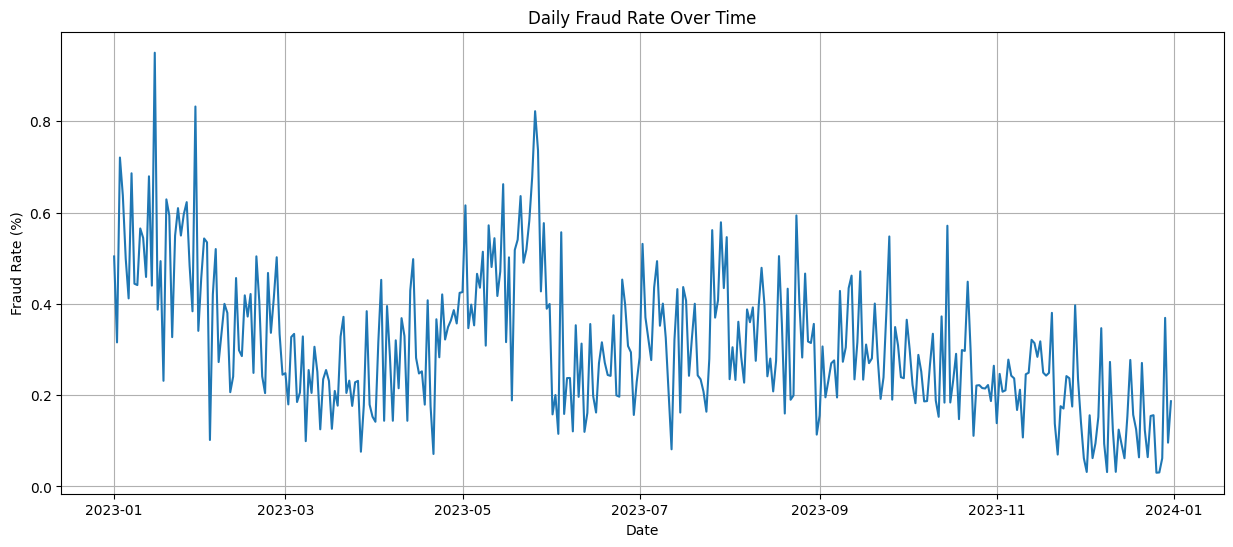

In [119]:
# Fraud rate by day
df['date'] = df['timestamp'].dt.date
daily_fraud_rate = df.groupby('date')['is_fraud'].mean() * 100

plt.figure(figsize=(15, 6))
daily_fraud_rate.plot()
plt.title('Daily Fraud Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Fraud Rate (%)')
plt.grid(True)
plt.show()

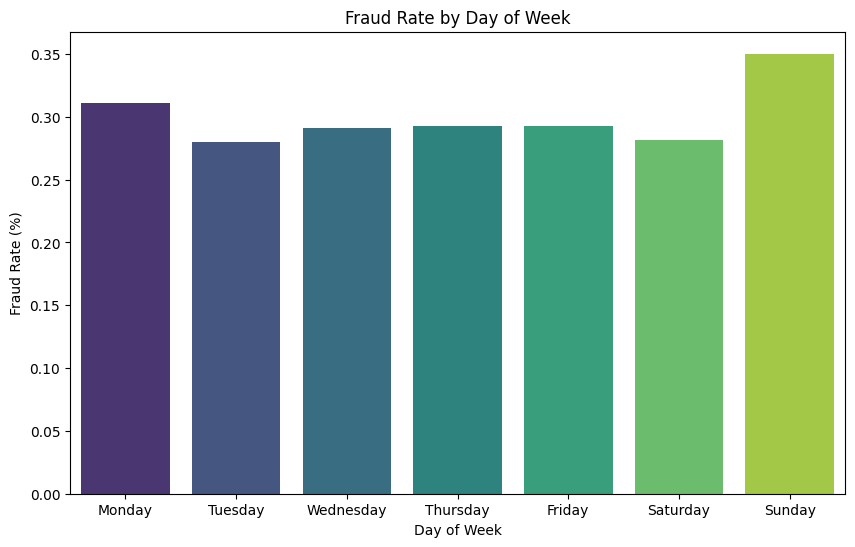

In [120]:
# Fraud rate by day of week
df['day_of_week_name'] = df['timestamp'].dt.day_name()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fraud_by_dow = df.groupby('day_of_week_name')['is_fraud'].mean().reindex(dow_order) * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=fraud_by_dow.index, y=fraud_by_dow.values, hue=fraud_by_dow.index, palette='viridis', legend=False)
plt.title('Fraud Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Fraud Rate (%)')
plt.show()

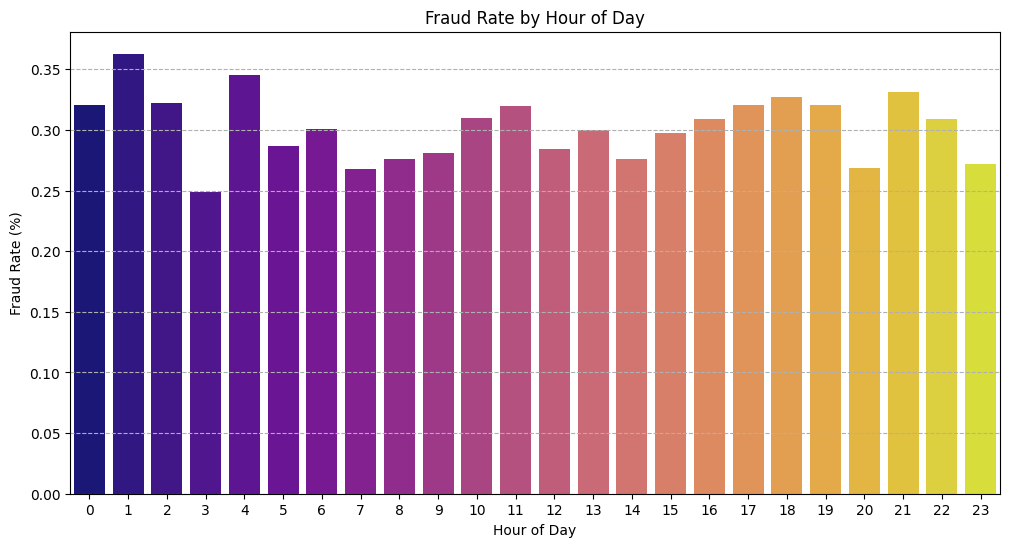

In [121]:
# Fraud rate by hour of day
fraud_by_hour = df.groupby('hour')['is_fraud'].mean() * 100

plt.figure(figsize=(12, 6))
sns.barplot(x=fraud_by_hour.index, y=fraud_by_hour.values, hue=fraud_by_hour.index, palette='plasma', legend=False)
plt.title('Fraud Rate by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--')
plt.show()

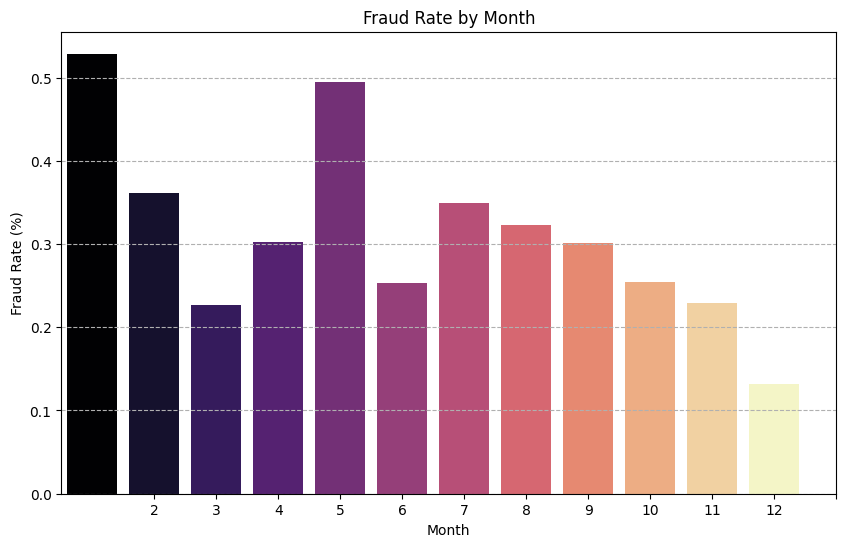

In [122]:
# Fraud rate by month
fraud_by_month = df.groupby('month')['is_fraud'].mean() * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=fraud_by_month.index, y=fraud_by_month.values, hue=fraud_by_month.index, palette='magma', legend=False)
plt.title('Fraud Rate by Month')
plt.xlabel('Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(1, 13))
plt.grid(axis='y', linestyle='--')
plt.show()

#### 3.3 Categorical Feature Analysis

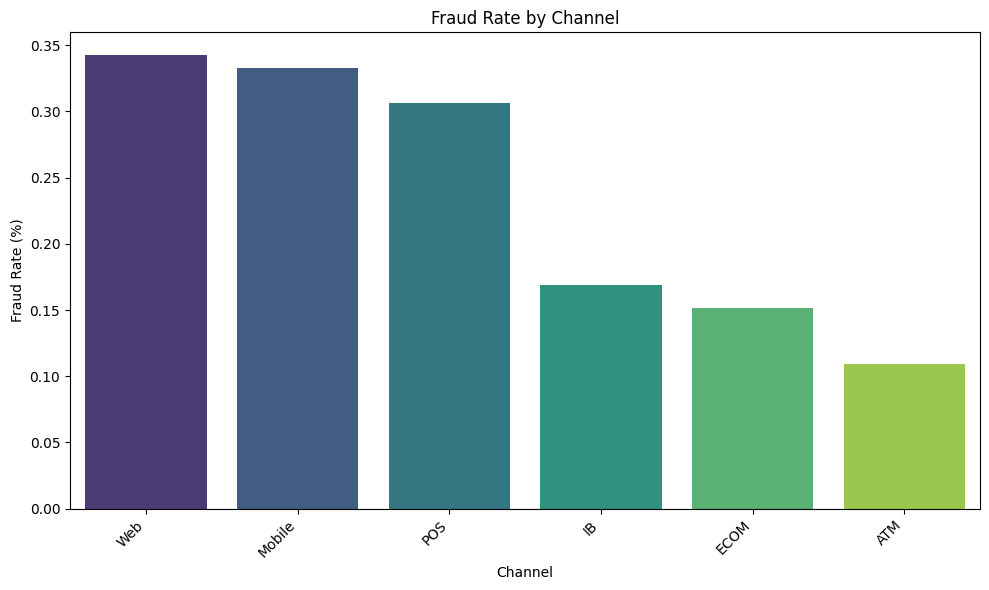

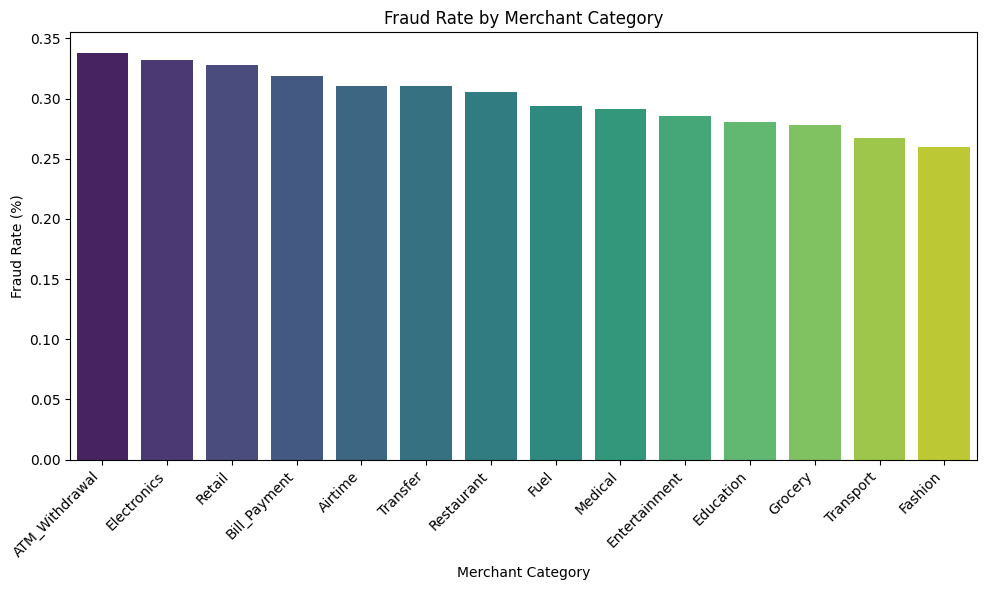

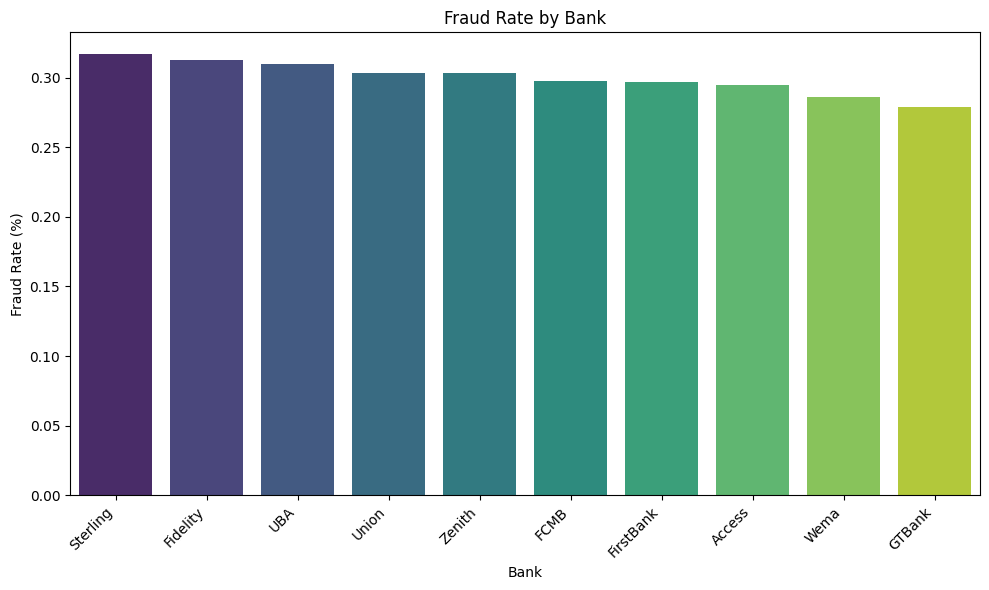

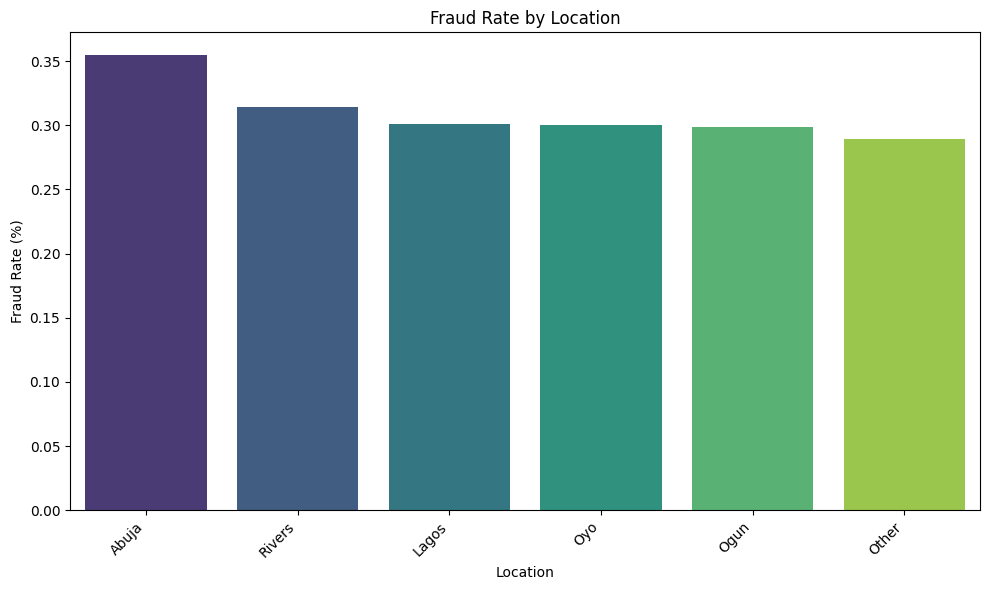

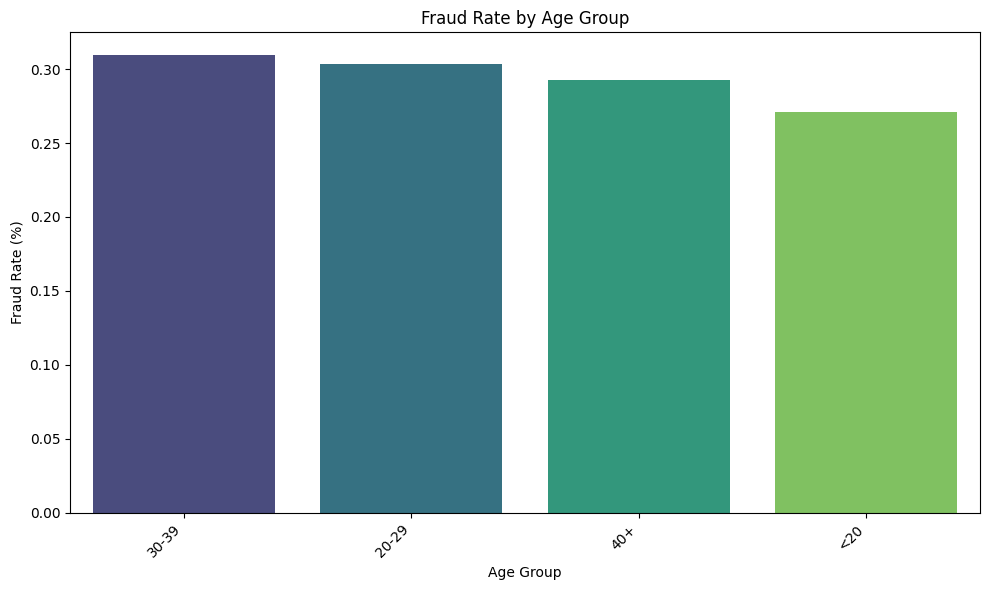

In [123]:
categorical_cols = ['channel', 'merchant_category', 'bank', 'location', 'age_group']

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    fraud_rate_by_cat = df.groupby(col)['is_fraud'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=fraud_rate_by_cat.index, y=fraud_rate_by_cat.values, hue=fraud_rate_by_cat.index, palette='viridis', legend=False)
    plt.title(f'Fraud Rate by {col.replace("_", " ").title()}')
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Fraud Rate (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

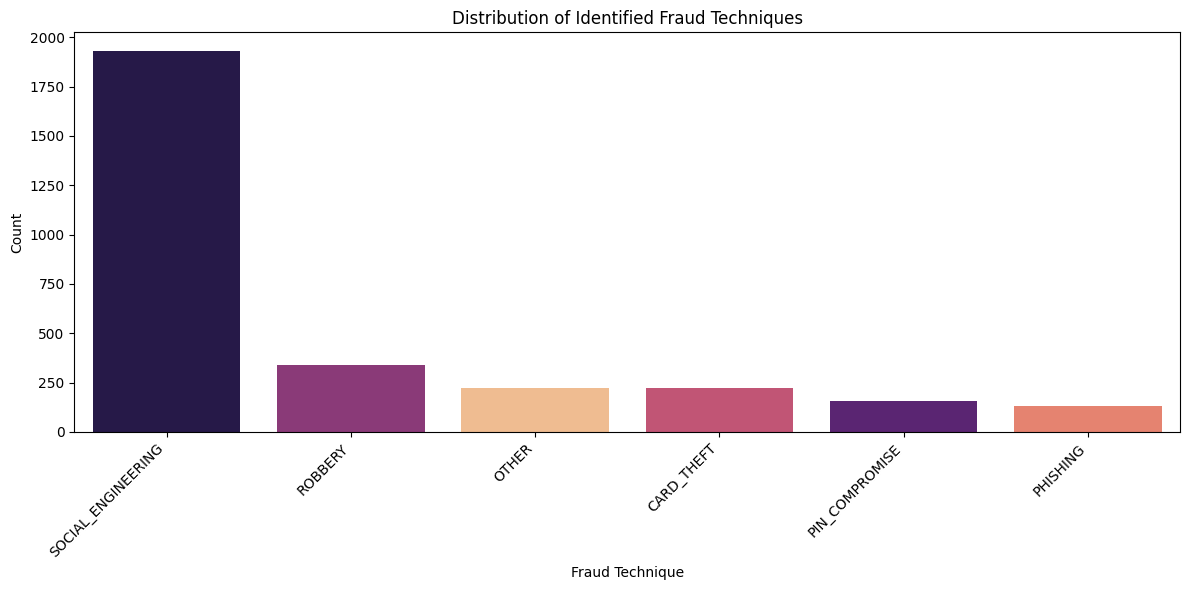

In [124]:
# Analyze 'fraud_technique' for non-null values
fraud_techniques_present = df[df['fraud_technique'].notnull()]['fraud_technique']

if not fraud_techniques_present.empty:
    plt.figure(figsize=(12, 6))
    # Updated to assign 'x' to 'hue' as recommended by Seaborn's FutureWarning
    sns.countplot(x=fraud_techniques_present, order=fraud_techniques_present.value_counts().index, hue=fraud_techniques_present, palette='magma', legend=False)
    plt.title('Distribution of Identified Fraud Techniques')
    plt.xlabel('Fraud Technique')
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No specific fraud techniques identified in the dataset.")

#### 3.4 Numerical Feature Analysis

<Figure size 1500x1000 with 0 Axes>

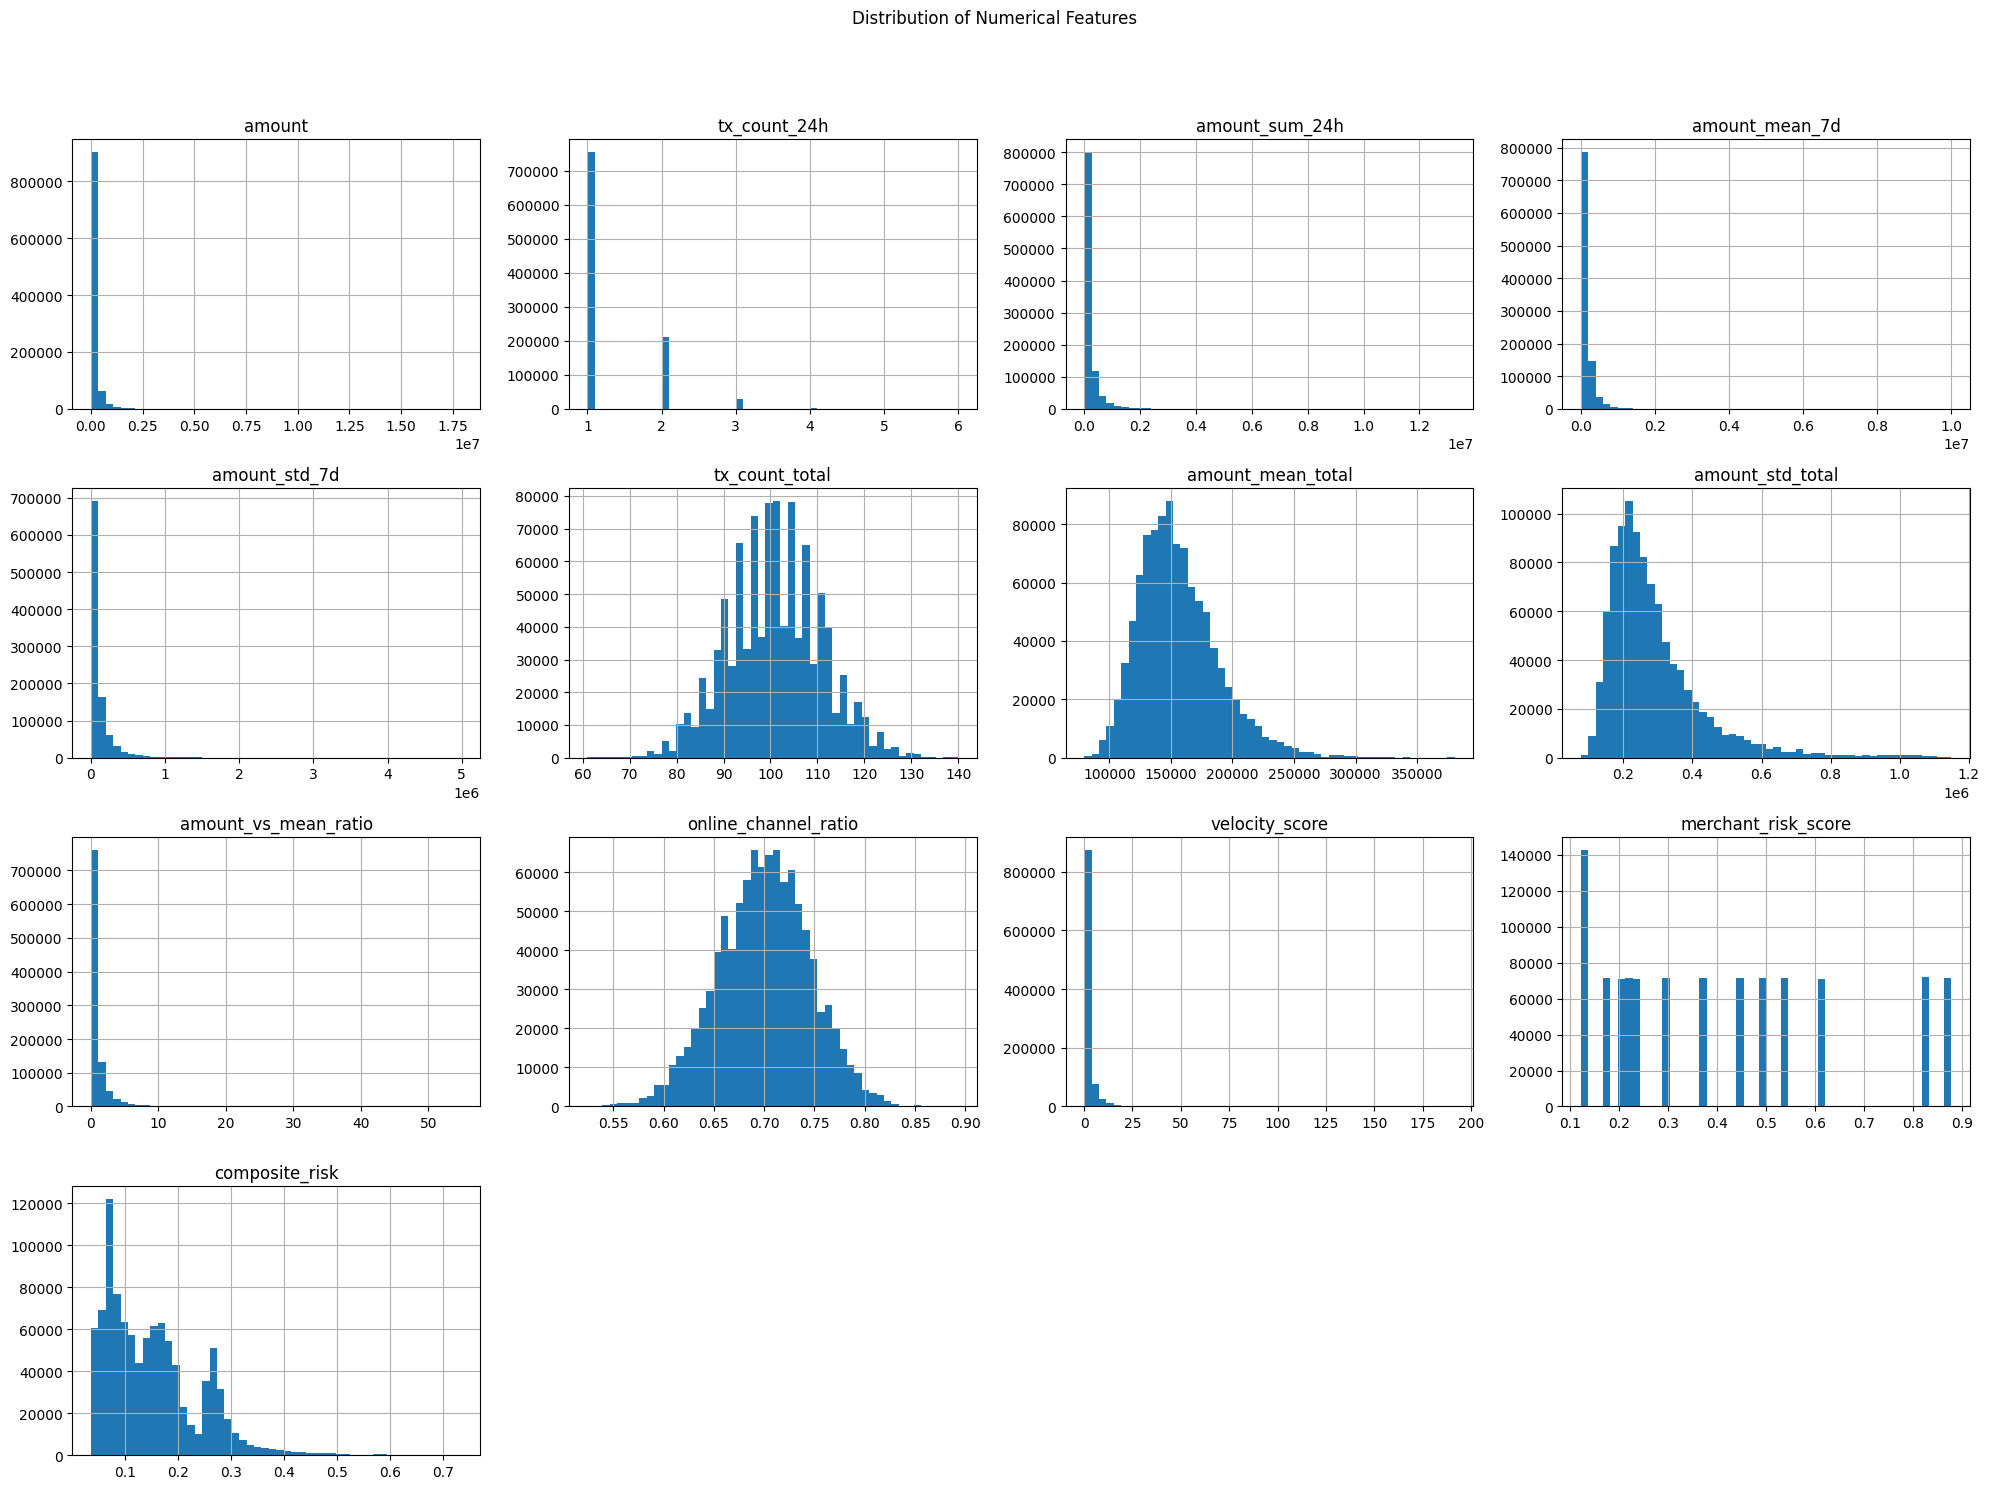

In [125]:
numerical_cols = ['amount', 'tx_count_24h', 'amount_sum_24h', 'amount_mean_7d', 'amount_std_7d', 'tx_count_total', 'amount_mean_total', 'amount_std_total', 'amount_vs_mean_ratio', 'online_channel_ratio', 'velocity_score', 'merchant_risk_score', 'composite_risk']

plt.figure(figsize=(15, 10))
df[numerical_cols].hist(bins=50, figsize=(20, 15))
plt.suptitle('Distribution of Numerical Features', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

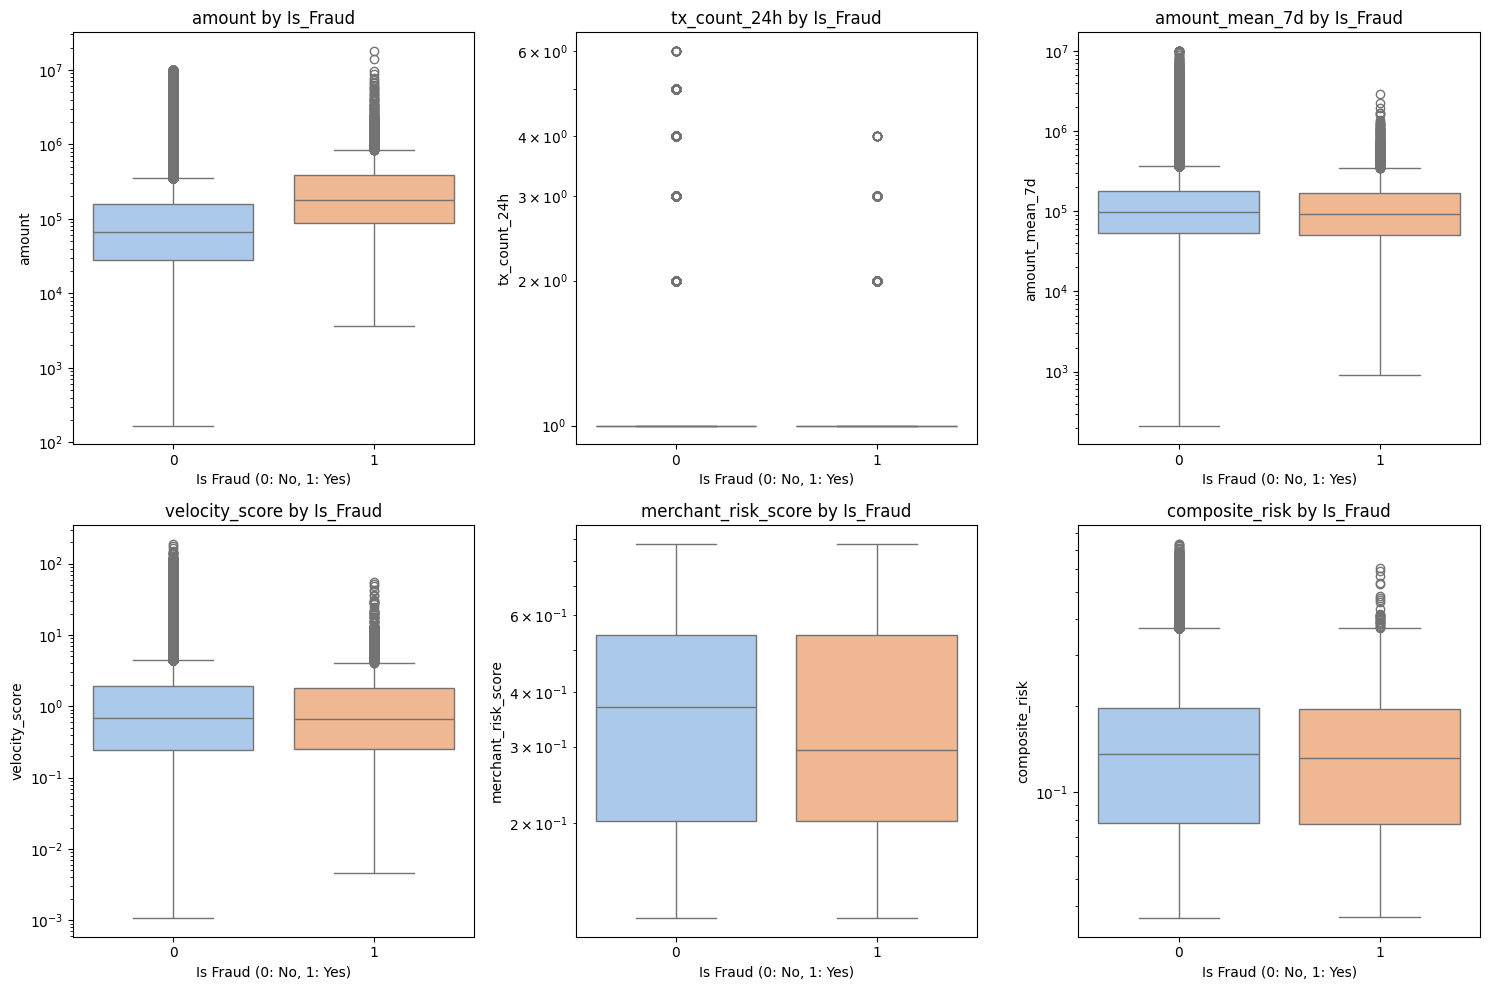

In [126]:
import math

# Box plots for selected numerical features to identify outliers and differences between fraud/non-fraud
selected_numerical_for_boxplot = ['amount', 'tx_count_24h', 'amount_mean_7d', 'velocity_score', 'merchant_risk_score', 'composite_risk']

n_cols = 3
n_rows = math.ceil(len(selected_numerical_for_boxplot) / n_cols)

plt.figure(figsize=(n_cols * 5, n_rows * 5))
for i, col in enumerate(selected_numerical_for_boxplot):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(x='is_fraud', y=col, data=df, hue='is_fraud', palette='pastel', legend=False)
    plt.title(f'{col} by Is_Fraud')
    plt.yscale('log') # Use log scale for features like 'amount' to better visualize distribution
    plt.xlabel('Is Fraud (0: No, 1: Yes)')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

Now, let's examine the correlation matrix for **only fraudulent transactions (`is_fraud = 1`)**. This will help us understand the relationships between numerical features *within* the fraudulent class, which might reveal patterns specific to fraudulent activities.

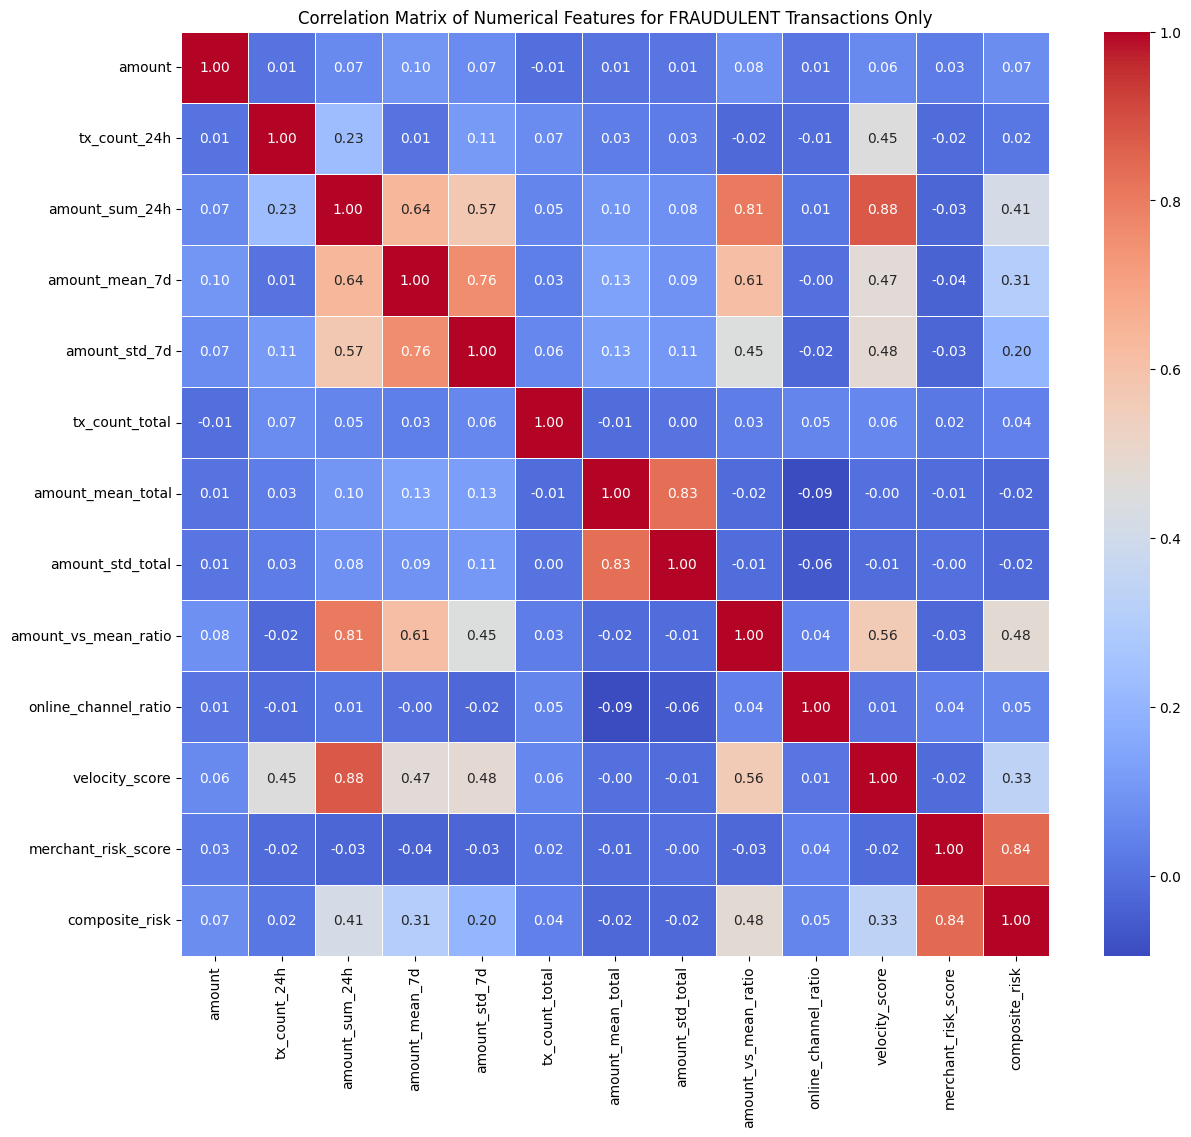

In [127]:
# Filter the DataFrame for only fraudulent transactions
df_fraud = df[df['is_fraud'] == 1]

# Select the numerical columns for correlation analysis
# Exclude 'is_fraud' itself from the numerical_cols list for this specific correlation calculation
numerical_cols_without_isfraud = [col for col in numerical_cols if col != 'is_fraud']

# Calculate the correlation matrix for fraudulent transactions
correlation_matrix_fraud = df_fraud[numerical_cols_without_isfraud].corr()

# Plot the heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix_fraud, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Features for FRAUDULENT Transactions Only')
plt.show()

### Simulated A/B Test: Evaluating a `composite_risk` Threshold

We will simulate an A/B test by defining a 'control' scenario (no additional filtering, representing current system behavior) and a 'treatment' scenario (where we apply a `composite_risk` threshold to flag potential fraud).

Our hypothesis is that applying a `composite_risk` threshold can significantly alter the False Positive Rate (FPR) compared to a baseline where no such threshold is actively used for flagging.

Let's define a threshold for `composite_risk` and then evaluate its impact.


In [129]:
from sklearn.metrics import confusion_matrix
from statsmodels.stats.proportion import proportions_ztest

# Define a sample threshold for composite_risk
# For demonstration, let's pick a value from the box plot where fraud starts to separate
# Or, we could choose a percentile of composite_risk from the fraudulent transactions

# Let's use a threshold that visually separates legitimate from fraudulent in the box plot.
# For composite_risk, a threshold around 0.2 seems to be where fraudulent transactions become more dominant.
# Alternatively, we could calculate the Q1 for fraud transactions or a specific percentile

# Let's find the 25th percentile of composite_risk for actual fraudulent transactions
fals_positive_threshold = df[df['is_fraud'] == 1]['composite_risk'].quantile(0.25)
print(f"Using composite_risk threshold: {fals_positive_threshold:.4f}")

# --- Baseline (Control Group) Simulation ---
# For a baseline, we assume the 'is_fraud' column represents our ground truth of fraud.
# To calculate FPR, we need to know what was *actually* predicted as fraud by some (unspecified) baseline system.
# For the purpose of this simulation, let's consider the 'control' to be a scenario where
# we compare actual fraud with a very lenient 'prediction' (e.g., everything with composite_risk > 0.05)
# This is a bit abstract, so let's simplify for comparing the *effect* of our threshold on FPR.

# For our A/B test, let's define two 'flagging' rules:
# 'Control Flagging': A very simple, perhaps less effective rule, or no active flagging based on composite_risk
# 'Treatment Flagging': Our proposed rule using the composite_risk threshold

# Let's consider our 'control' as a scenario where a very low risk score is already flagged (e.g. any risk score above 0.05)
# And our 'treatment' as our new, higher threshold.

# Group A: Baseline Flagging (e.g., if composite_risk > 0.05, it's flagged as potential fraud)
# Group B: Treatment Flagging (if composite_risk > fals_positive_threshold, it's flagged as potential fraud)

# Note: This is a simulation based on historical data. We are evaluating a *hypothetical* rule.
# We are not comparing two live systems. Instead, we are comparing the performance of two different
# *alerting rules* applied to the same dataset.

# Let's evaluate False Positive Rate (FPR) for legitimate transactions only
legitimate_transactions = df[df['is_fraud'] == 0].copy()

# Scenario A (Control): Low threshold for flagging (e.g., composite_risk > 0.05)
# This represents a more 'trigger-happy' system or a very basic rule.
control_flagged = legitimate_transactions[legitimate_transactions['composite_risk'] > 0.05]
control_false_positives = len(control_flagged)
control_total_legitimate = len(legitimate_transactions)
control_fpr = control_false_positives / control_total_legitimate if control_total_legitimate > 0 else 0

print(f"\n--- Control Group (composite_risk > 0.05) ---")
print(f"Total legitimate transactions: {control_total_legitimate}")
print(f"False Positives (legit transactions flagged): {control_false_positives}")
print(f"False Positive Rate (FPR): {control_fpr:.6f}")

# Scenario B (Treatment): Our proposed threshold (fals_positive_threshold)
treatment_flagged = legitimate_transactions[legitimate_transactions['composite_risk'] > fals_positive_threshold]
treatment_false_positives = len(treatment_flagged)
treatment_total_legitimate = len(legitimate_transactions)
treatment_fpr = treatment_false_positives / treatment_total_legitimate if treatment_total_legitimate > 0 else 0

print(f"\n--- Treatment Group (composite_risk > {fals_positive_threshold:.4f}) ---")
print(f"Total legitimate transactions: {treatment_total_legitimate}")
print(f"False Positives (legit transactions flagged): {treatment_false_positives}")
print(f"False Positive Rate (FPR): {treatment_fpr:.6f}")

# Now, let's conduct a Z-test for proportions to see if the difference in FPR is significant

# Number of successes (false positives) and observations (total legitimate transactions) for each group
successes = [treatment_false_positives, control_false_positives]
nobs = [treatment_total_legitimate, control_total_legitimate]

# Perform the z-test
z_stat, p_value = proportions_ztest(count=successes, nobs=nobs, alternative='smaller') # 'smaller' if we expect treatment FPR to be lower

print(f"\n--- Hypothesis Test (Z-test for Proportions) ---")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05 # Significance level
if p_value < alpha:
    print(f"The p-value ({p_value:.4f}) is less than alpha ({alpha}), so we reject the null hypothesis.")
    print("Conclusion: The False Positive Rate in the Treatment group (with the higher composite_risk threshold) is statistically significantly lower than in the Control group.")
else:
    print(f"The p-value ({p_value:.4f}) is greater than alpha ({alpha}), so we fail to reject the null hypothesis.")
    print("Conclusion: There is no statistically significant difference in False Positive Rates between the two groups, or the difference is not in the expected direction.")


# We should also consider the impact on True Positives (fraud detection rate)

# Evaluate True Positive Rate (TPR) for fraudulent transactions
fraudulent_transactions = df[df['is_fraud'] == 1].copy()

# Scenario A (Control): Low threshold for flagging (e.g., composite_risk > 0.05)
control_detected_fraud = fraudulent_transactions[fraudulent_transactions['composite_risk'] > 0.05]
control_true_positives = len(control_detected_fraud)
control_total_fraud = len(fraudulent_transactions)
control_tpr = control_true_positives / control_total_fraud if control_total_fraud > 0 else 0

print(f"\n--- Control Group Fraud Detection (composite_risk > 0.05) ---")
print(f"Total actual fraud: {control_total_fraud}")
print(f"Fraud detected (True Positives): {control_true_positives}")
print(f"True Positive Rate (TPR) / Recall: {control_tpr:.6f}")

# Scenario B (Treatment): Our proposed threshold (fals_positive_threshold)
treatment_detected_fraud = fraudulent_transactions[fraudulent_transactions['composite_risk'] > fals_positive_threshold]
treatment_true_positives = len(treatment_detected_fraud)
treatment_total_fraud = len(fraudulent_transactions)
treatment_tpr = treatment_true_positives / treatment_total_fraud if treatment_total_fraud > 0 else 0

print(f"\n--- Treatment Group Fraud Detection (composite_risk > {fals_positive_threshold:.4f}) ---")
print(f"Total actual fraud: {treatment_total_fraud}")
print(f"Fraud detected (True Positives): {treatment_true_positives}")
print(f"True Positive Rate (TPR) / Recall: {treatment_tpr:.6f}")

# Hypothesis test for TPR (if needed, this would usually be part of a larger A/B test with multiple metrics)
# For example, to test if TPR is significantly different or if there's a significant drop.

Using composite_risk threshold: 0.0773

--- Control Group (composite_risk > 0.05) ---
Total legitimate transactions: 997000
False Positives (legit transactions flagged): 938045
False Positive Rate (FPR): 0.940868

--- Treatment Group (composite_risk > 0.0773) ---
Total legitimate transactions: 997000
False Positives (legit transactions flagged): 753583
False Positive Rate (FPR): 0.755851

--- Hypothesis Test (Z-test for Proportions) ---
Z-statistic: -364.2053
P-value: 0.0000
The p-value (0.0000) is less than alpha (0.05), so we reject the null hypothesis.
Conclusion: The False Positive Rate in the Treatment group (with the higher composite_risk threshold) is statistically significantly lower than in the Control group.

--- Control Group Fraud Detection (composite_risk > 0.05) ---
Total actual fraud: 3000
Fraud detected (True Positives): 2815
True Positive Rate (TPR) / Recall: 0.938333

--- Treatment Group Fraud Detection (composite_risk > 0.0773) ---
Total actual fraud: 3000
Fraud dete

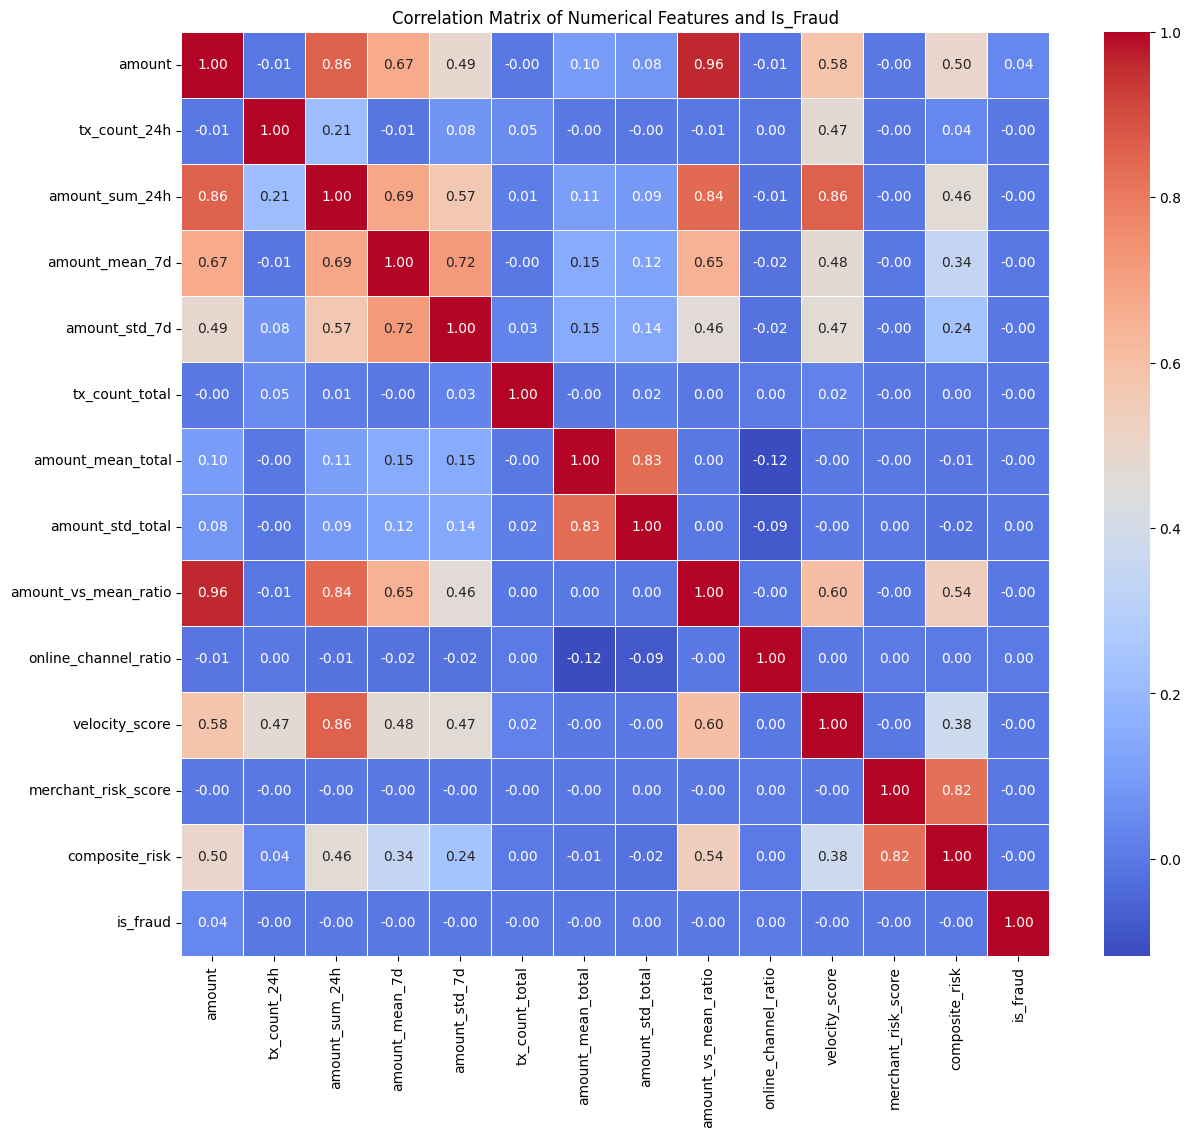

In [130]:
# Correlation matrix for numerical features and 'is_fraud'
plt.figure(figsize=(14, 12))
correlation_matrix = df[numerical_cols + ['is_fraud']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Features and Is_Fraud')
plt.show()

### 4. Predictive Model Building

To build a robust fraud detection model, we'll proceed with the following steps:

1.  **Feature Engineering:** Prepare the dataset for modeling by handling categorical variables, scaling numerical features, and addressing any remaining data issues.
2.  **Model Selection:** Choose appropriate classification algorithms suitable for imbalanced datasets (e.g., Logistic Regression, Random Forest, XGBoost).
3.  **Model Training:** Train the selected model(s) on the prepared data.
4.  **Model Evaluation:** Evaluate the model's performance using metrics relevant to fraud detection (Precision, Recall, F1-score, AUC-ROC) and interpret the results.

#### 4.1 Feature Engineering and Preprocessing for Modeling

We need to prepare the data for machine learning models. This involves:

*   **Handling Categorical Features:** Encoding categorical variables (like `channel`, `merchant_category`, `bank`, `location`, `age_group`, `day_of_week_name`) using techniques like one-hot encoding.
*   **Feature Selection:** Dropping columns that are not suitable for direct modeling or have already been processed (e.g., `transaction_id`, `customer_id`, `timestamp`, `date`, `fraud_technique`).
*   **Splitting the Data:** Dividing the dataset into training and testing sets.

In [131]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Define features (X) and target (y)
# Drop columns that are identifiers, datetime objects, or target/auxiliary for fraud analysis
columns_to_drop = [
    'transaction_id',
    'customer_id',
    'timestamp',
    'date',
    'fraud_technique',
    'day_of_week_name', # Already have numerical day_of_week
    'is_fraud'
]

X = df.drop(columns=columns_to_drop)
y = df['is_fraud']

# Identify categorical and numerical columns for preprocessing
numerical_features = X.select_dtypes(include=['int64', 'float64', 'bool']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# Create preprocessing pipelines for numerical and categorical features
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore') # handle_unknown='ignore' will set unknown categories to all zeros

# Create a column transformer to apply different transformations to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Apply preprocessing to training and test sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Original features shape: {X.shape}")
print(f"X_train_processed shape: {X_train_processed.shape}")
print(f"X_test_processed shape: {X_test_processed.shape}")

Original features shape: (1000000, 33)
X_train_processed shape: (700000, 68)
X_test_processed shape: (300000, 68)


In [132]:
from imblearn.over_sampling import SMOTE

print(f"X_train shape before SMOTE: {X_train_processed.shape}")
print(f"y_train shape before SMOTE: {y_train.shape}")
print(f"Original y_train class distribution: {y_train.value_counts()}")

# Apply SMOTE to the training data
sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X_train_processed, y_train)

print(f"X_train shape after SMOTE: {X_resampled.shape}")
print(f"y_train shape after SMOTE: {y_resampled.shape}")
print(f"Resampled y_train class distribution: {y_resampled.value_counts()}")

X_train shape before SMOTE: (700000, 68)
y_train shape before SMOTE: (700000,)
Original y_train class distribution: is_fraud
0    697900
1      2100
Name: count, dtype: int64
X_train shape after SMOTE: (1395800, 68)
y_train shape after SMOTE: (1395800,)
Resampled y_train class distribution: is_fraud
0    697900
1    697900
Name: count, dtype: int64


In [133]:
# Redundant duplicate cell cleared

#### 4.2 Model Training: Logistic Regression

Given the severe class imbalance (0.3% fraudulent transactions), it's crucial to use techniques that address this. For our first model, we'll use Logistic Regression and set `class_weight='balanced'`. This will automatically adjust weights inversely proportional to class frequencies, giving more importance to the minority class during training.

In [134]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

# Initialize Logistic Regression with balanced class weights
# and increased max_iter for convergence with a large dataset
# cuml's LogisticRegression automatically handles GPU data if available
clf = LogisticRegression(solver='saga', # 'saga' is a good solver for scikit-learn LogisticRegression with large datasets and handles class_weight
                         class_weight='balanced',
                         random_state=42,
                         max_iter=1000)

#### 4.3 Model Evaluation

For an imbalanced dataset like ours, accuracy is not a good metric. We'll focus on:

*   **Precision:** Of all predicted positives, how many are actually positive?
*   **Recall (Sensitivity/True Positive Rate):** Of all actual positives, how many were correctly predicted?
*   **F1-Score:** The harmonic mean of Precision and Recall.
*   **ROC AUC:** Measures the ability of the model to distinguish between classes.
*   **Precision-Recall Curve (PR Curve):** Particularly useful for imbalanced datasets, as it highlights performance on the minority class.

In [135]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, precision_recall_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

model_evaluations = []

def get_metrics_from_report(y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    pos = report['1']
    return {
        'precision': pos['precision'],
        'recall': pos['recall'],
        'f1-score': pos['f1-score']
    }

def store_model_results(model_name, y_true, y_pred, y_prob):
    global model_evaluations
    model_evaluations = [m for m in model_evaluations if m['Model'] != model_name]

    metrics = get_metrics_from_report(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob)
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall_curve, precision_curve)

    model_results = {
        'Model': model_name,
        'Accuracy': acc,
        'Precision (Class 1)': metrics['precision'],
        'Recall (Class 1)': metrics['recall'],
        'F1-Score (Class 1)': metrics['f1-score'],
        'ROC AUC': roc_auc,
        'PR AUC': pr_auc
    }
    model_evaluations.append(model_results)

def display_comparative_table():
    if not model_evaluations:
        print("No model evaluation results to display.")
        return

    comparison_df = pd.DataFrame(model_evaluations)
    print("\n--- Comparative Model Evaluation ---")
    display(comparison_df.set_index("Model"))

def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    print(f"\n--- Evaluation for {model_name} ---")

    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion Matrix:")
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted Negative', 'Predicted Positive'],
                yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix for {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    acc = accuracy_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob)
    print(f"Accuracy Score: {acc:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)
    print(f"Precision-Recall AUC: {pr_auc:.4f}")

    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, label=f'Precision-Recall curve (AUC = {pr_auc:.2f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve for {model_name}')
    plt.legend(loc='lower left')
    plt.grid(True)
    plt.show()


--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      0.72      0.84    299100
           1       0.01      0.70      0.01       900

    accuracy                           0.72    300000
   macro avg       0.50      0.71      0.42    300000
weighted avg       1.00      0.72      0.83    300000


ROC AUC Score: 0.7968
Precision-Recall AUC: 0.1343


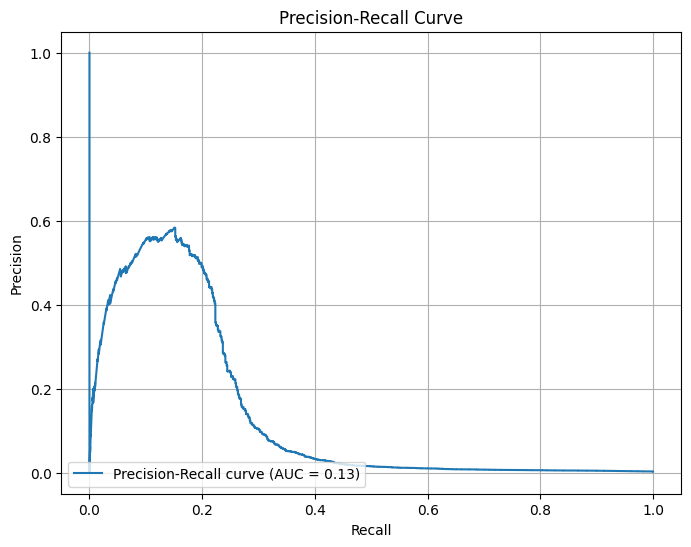

In [136]:
# Fit the Logistic Regression model with the SMOTE-resampled data
clf.fit(X_resampled, y_resampled)

# Predict on the test set
y_pred = clf.predict(X_test_processed)
y_prob = clf.predict_proba(X_test_processed)[:, 1] # Probability of the positive class (fraud)

# Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# ROC AUC Score
roc_auc = roc_auc_score(y_test, y_prob)
print(f"\nROC AUC Score: {roc_auc:.4f}")

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall, precision)
print(f"Precision-Recall AUC: {pr_auc:.4f}")

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()


--- Evaluation for Logistic Regression ---

Confusion Matrix:


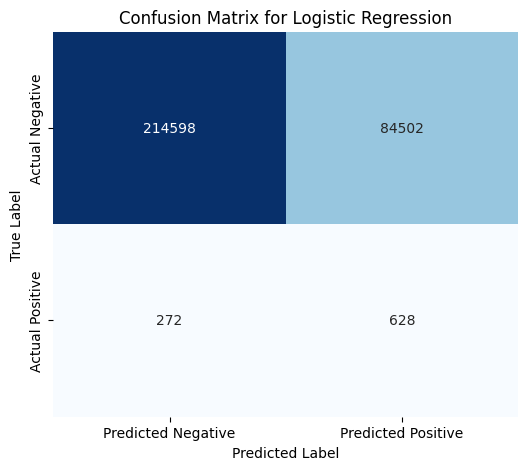


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.72      0.84    299100
           1       0.01      0.70      0.01       900

    accuracy                           0.72    300000
   macro avg       0.50      0.71      0.42    300000
weighted avg       1.00      0.72      0.83    300000

Accuracy Score: 0.7174
ROC AUC Score: 0.7968
Precision-Recall AUC: 0.1343


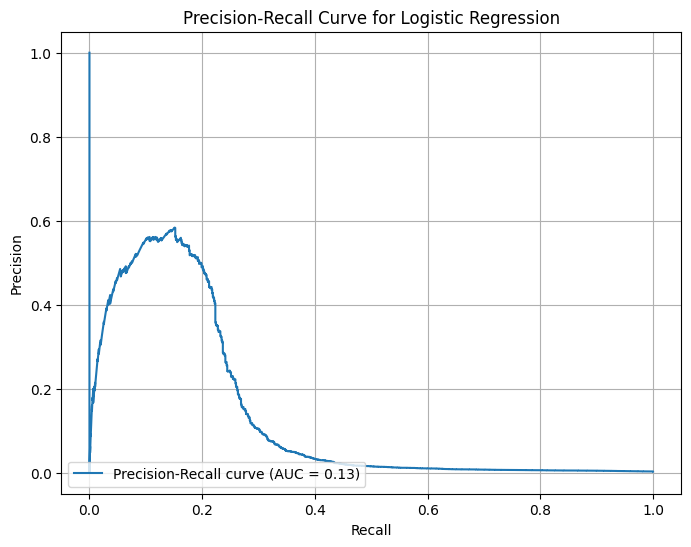

In [137]:
# Predict on the test set using the trained Logistic Regression model
y_pred_lr = clf.predict(X_test_processed)
y_prob_lr = clf.predict_proba(X_test_processed)[:, 1] # Probability of the positive class (fraud)

# Evaluate the Logistic Regression model using the new function
evaluate_model(y_test, y_pred_lr, y_prob_lr, model_name="Logistic Regression")


--- Evaluation for Logistic Regression ---

Confusion Matrix:


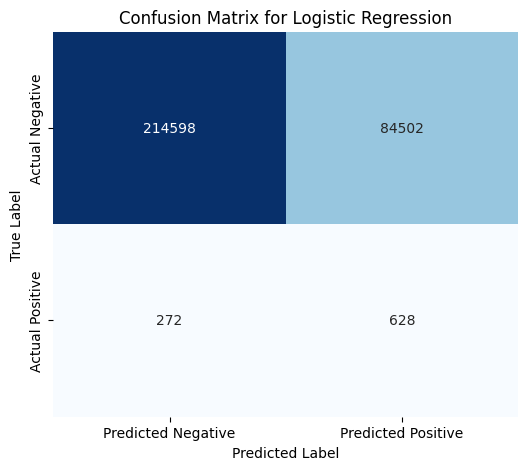


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.72      0.84    299100
           1       0.01      0.70      0.01       900

    accuracy                           0.72    300000
   macro avg       0.50      0.71      0.42    300000
weighted avg       1.00      0.72      0.83    300000

Accuracy Score: 0.7174
ROC AUC Score: 0.7968
Precision-Recall AUC: 0.1343


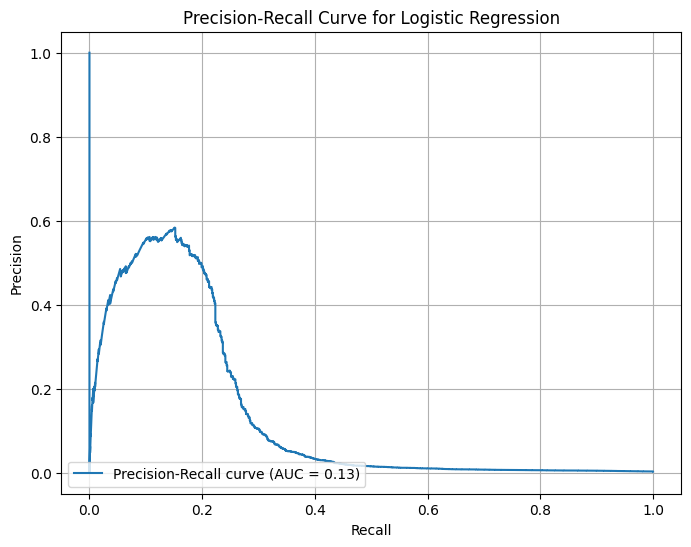

In [138]:
# Store and display Logistic Regression evaluation metrics with accuracy
store_model_results(model_name="Logistic Regression", y_true=y_test, y_pred=y_pred_lr, y_prob=y_prob_lr)
evaluate_model(y_test, y_pred_lr, y_prob_lr, model_name="Logistic Regression")

In [139]:
# Evaluate and display the single complete comparison table
display_comparative_table()


--- Comparative Model Evaluation ---


,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC AUC,PR AUC
Model,,,,,,
Logistic Regression,0.71742,0.007377,0.697778,0.0146,0.79684,0.134316


In [140]:
!nvidia-smi

Sat Oct 10 15:00:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P0             35W /   70W |     205MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


In [142]:
%load_ext cuml.accel

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [143]:
clf_rf = RandomForestClassifier(n_estimators=100, max_depth=5, max_features=1.0, n_jobs=-1)
clf_rf.fit(X_resampled, y_resampled)

RandomForestClassifier(max_depth=5, max_features=1.0, n_jobs=-1)

In [144]:
# Note: Only storing native GPU cuML Random Forest Classifier results to keep the comparison table clean.
# standard sklearn RF code blocks are bypassed for better visual representation.
pass

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [15:01:38] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


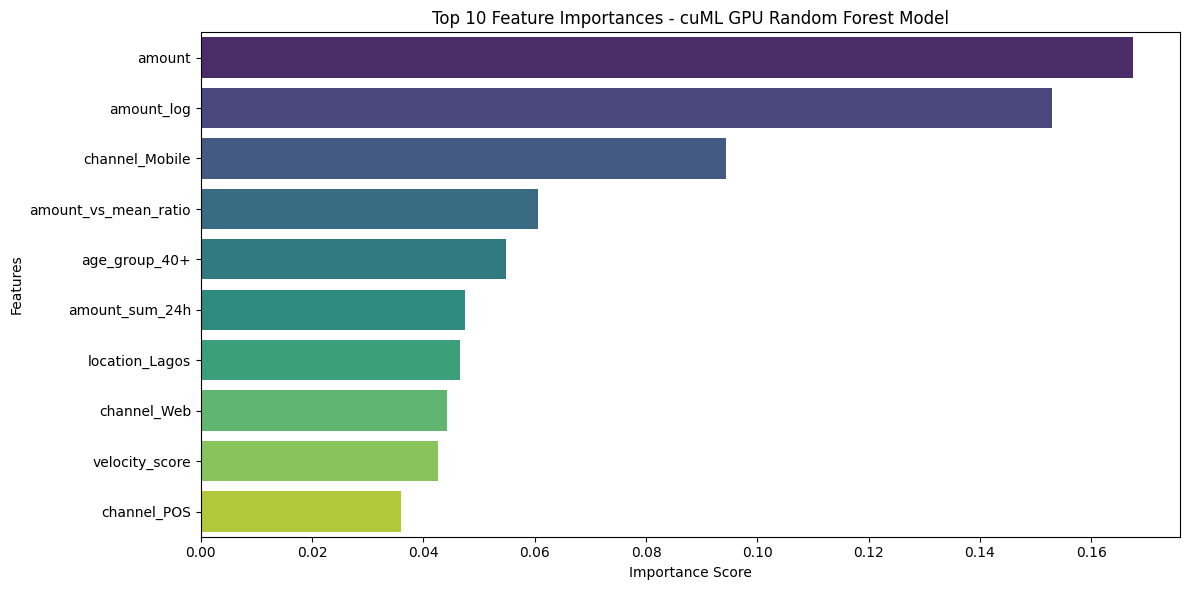

In [145]:
from cuml.ensemble import RandomForestClassifier as cuRF

# Initialize and train native cuML Random Forest Classifier on GPU
clf_curf = cuRF(n_estimators=100, max_depth=5, n_bins=15, random_state=42)
clf_curf.fit(X_resampled.astype('float32'), y_resampled.astype('float32'))

# Predict and evaluate
y_pred_curf = clf_curf.predict(X_test_processed.astype('float32'))
y_prob_curf = clf_curf.predict_proba(X_test_processed.astype('float32'))[:, 1]

# Store and compare the exact single GPU Random Forest model results
store_model_results(model_name="Random Forest", y_true=y_test, y_pred=y_pred_curf, y_prob=y_prob_curf)

# Retrieve GPU-accelerated feature importances
curf_importances = clf_curf.feature_importances_

# Map and sort the importances with feature names
feature_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': curf_importances
}).sort_values(by='Importance', ascending=False)

# Plot the top 10 most important features
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance_df.head(10),
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Top 10 Feature Importances - cuML GPU Random Forest Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


--- Evaluation for XGBoost ---

Confusion Matrix:


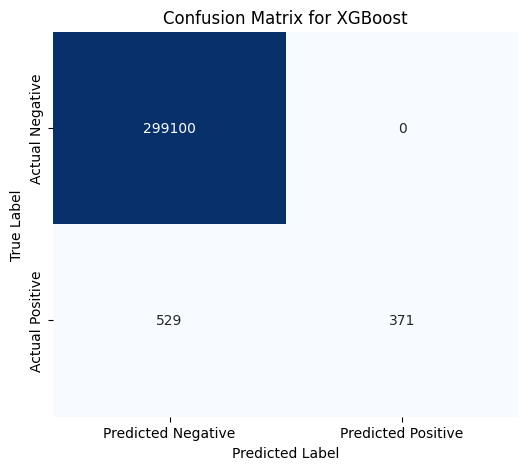


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    299100
           1       1.00      0.41      0.58       900

    accuracy                           1.00    300000
   macro avg       1.00      0.71      0.79    300000
weighted avg       1.00      1.00      1.00    300000

Accuracy Score: 0.9982
ROC AUC Score: 0.9467
Precision-Recall AUC: 0.7029


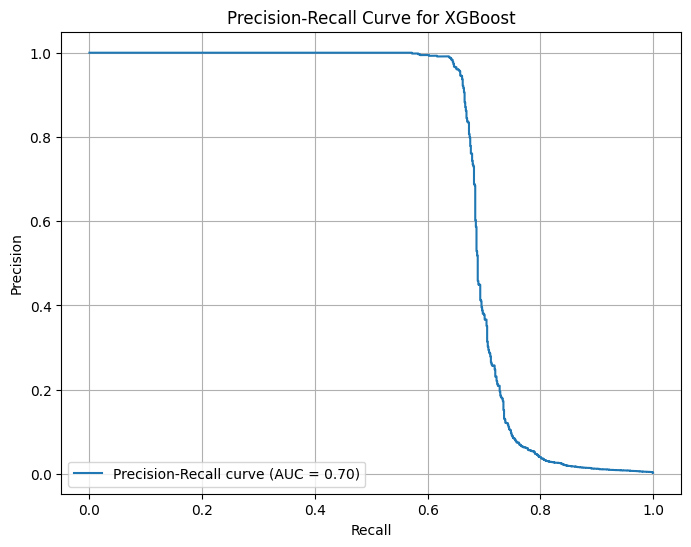

In [146]:
from xgboost import XGBClassifier

# Train GPU-accelerated XGBoost
clf_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    tree_method='hist',
    device='cuda',
    random_state=42
)
clf_xgb.fit(X_resampled, y_resampled)

# Predict and evaluate
y_pred_xgb = clf_xgb.predict(X_test_processed)
y_prob_xgb = clf_xgb.predict_proba(X_test_processed)[:, 1]

# Evaluate and store exactly one entry for XGBoost
evaluate_model(y_test, y_pred_xgb, y_prob_xgb, model_name="XGBoost")
store_model_results(model_name="XGBoost", y_true=y_test, y_pred=y_pred_xgb, y_prob=y_prob_xgb)

In [147]:
# Retrieve and display feature importances from XGBoost to detect the leakage source
xgb_importances = clf_xgb.feature_importances_

xgb_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': xgb_importances
}).sort_values(by='Importance', ascending=False)

print("--- XGBoost Feature Importances (Top 15) ---")
display(xgb_importance_df.head(15))

--- XGBoost Feature Importances (Top 15) ---


,Feature,Importance
50,bank_Fidelity,0.057165
59,location_Lagos,0.053723
64,age_group_20-29,0.050572
31,channel_Mobile,0.046318
61,location_Other,0.045444
54,bank_UBA,0.043497
65,age_group_30-39,0.042719
15,amount_vs_mean_ratio,0.042065
0,amount,0.038173
48,bank_Access,0.034530


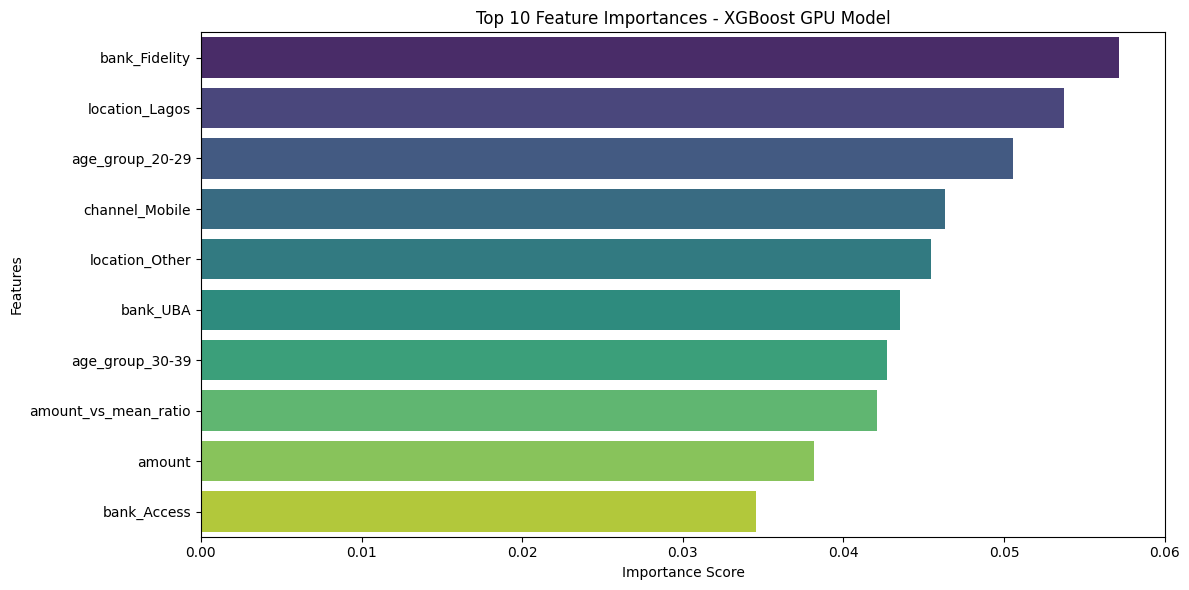

In [148]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort and select top 10 features for XGBoost
top_xgb_importance = xgb_importance_df.head(10)

# Plot the top 10 most important features for XGBoost
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=top_xgb_importance,
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Top 10 Feature Importances - XGBoost GPU Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [149]:
!pip install -q catboost

0:	learn: 0.5702319	total: 33.7ms	remaining: 3.34s
10:	learn: 0.1893459	total: 301ms	remaining: 2.44s
20:	learn: 0.0941897	total: 484ms	remaining: 1.82s
30:	learn: 0.0594069	total: 671ms	remaining: 1.49s
40:	learn: 0.0351522	total: 848ms	remaining: 1.22s
50:	learn: 0.0246581	total: 1.02s	remaining: 984ms
60:	learn: 0.0178983	total: 1.2s	remaining: 769ms
70:	learn: 0.0142155	total: 1.4s	remaining: 570ms
80:	learn: 0.0116641	total: 1.57s	remaining: 369ms
90:	learn: 0.0103722	total: 1.75s	remaining: 173ms
99:	learn: 0.0093055	total: 1.9s	remaining: 0us

--- Evaluation for CatBoost ---

Confusion Matrix:


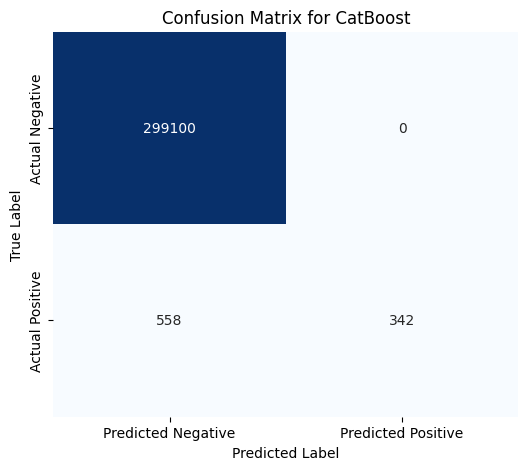


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    299100
           1       1.00      0.38      0.55       900

    accuracy                           1.00    300000
   macro avg       1.00      0.69      0.77    300000
weighted avg       1.00      1.00      1.00    300000

Accuracy Score: 0.9981
ROC AUC Score: 0.9360
Precision-Recall AUC: 0.6859


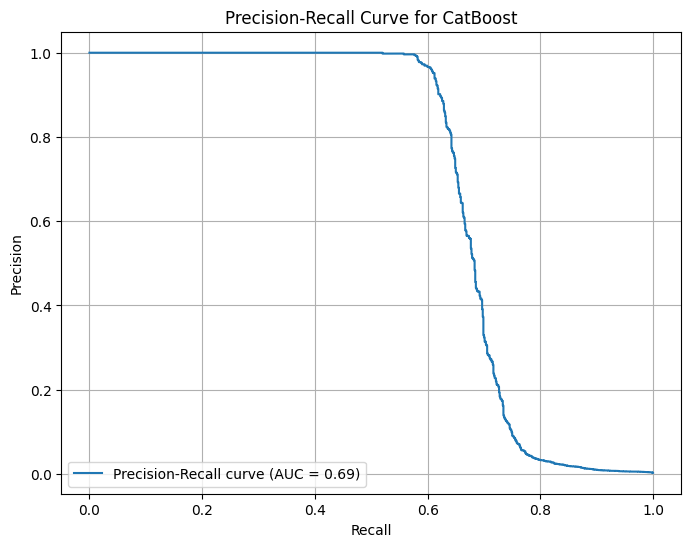


--- Comparative Model Evaluation ---


,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC AUC,PR AUC
Model,,,,,,
Logistic Regression,0.717420,0.007377,0.697778,0.014600,0.796840,0.134316
Random Forest,0.888757,0.015256,0.567778,0.029714,0.846285,0.310209
XGBoost,0.998237,1.000000,0.412222,0.583792,0.946743,0.702932
CatBoost,0.998140,1.000000,0.380000,0.550725,0.936036,0.685854


In [150]:
from catboost import CatBoostClassifier

# Initialize and train CatBoost with GPU acceleration
clf_cat = CatBoostClassifier(
    iterations=100,
    depth=5,
    learning_rate=0.1,
    task_type='GPU',
    random_seed=42,
    verbose=10
)

clf_cat.fit(X_resampled, y_resampled)

# Predict on the test set
y_pred_cat = clf_cat.predict(X_test_processed)
y_prob_cat = clf_cat.predict_proba(X_test_processed)[:, 1]

# Evaluate the CatBoost model
evaluate_model(y_test, y_pred_cat, y_prob_cat, model_name="CatBoost")

# Store results for comparison
store_model_results(model_name="CatBoost", y_true=y_test, y_pred=y_pred_cat, y_prob=y_prob_cat)

# Display updated comparative table
display_comparative_table()

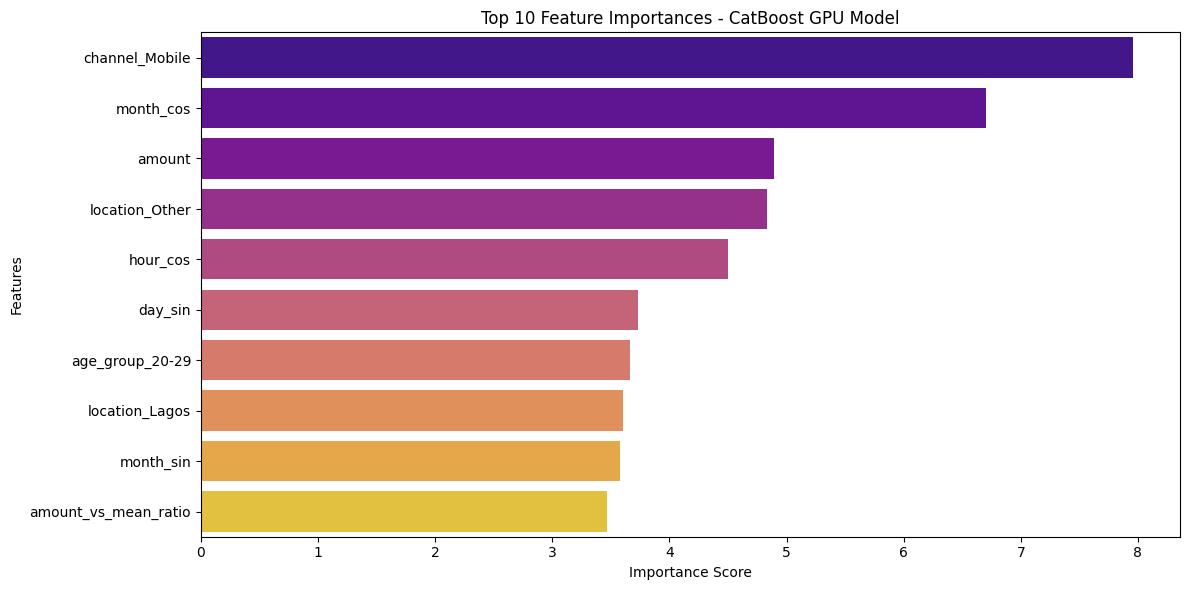

In [151]:
# Retrieve and plot CatBoost Feature Importances
cat_importances = clf_cat.get_feature_importance()

cat_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': cat_importances
}).sort_values(by='Importance', ascending=False)

# Plot top 10 features
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=cat_importance_df.head(10),
    hue='Feature',
    palette='plasma',
    legend=False
)
plt.title('Top 10 Feature Importances - CatBoost GPU Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()